In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
orders_raw = pd.read_csv("data/olist_orders_dataset.csv")
items = pd.read_csv("data/olist_order_items_dataset.csv")
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")
customers = pd.read_csv("data/olist_customers_dataset.csv")
sellers = pd.read_csv("data/olist_sellers_dataset.csv")
geo = pd.read_csv("data/olist_geolocation_dataset.csv")

for name, df in [("orders", orders_raw), ("items", items), ("reviews", reviews), ("customers", customers), ("sellers", sellers), ("geo", geo)]:
    print(f"{name:<10} {df.shape}")

orders     (99441, 8)
items      (112650, 7)
reviews    (99224, 7)
customers  (99441, 5)
sellers    (3095, 4)
geo        (1000163, 5)


In [3]:
delivered = orders_raw[orders_raw["order_status"] == "delivered"].copy()
for col in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    delivered[col] = pd.to_datetime(delivered[col])

one_day = pd.Timedelta(days=1)
delivered["wait_time"] = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]) / one_day
delivered["expected_wait_time"] = (delivered["order_estimated_delivery_date"] - delivered["order_purchase_timestamp"]) / one_day
delivered["delay_vs_expected"] = ((delivered["order_delivered_customer_date"] - delivered["order_estimated_delivery_date"]) / one_day).clip(lower=0)

print("Teslim edilen sipariş:", len(delivered))
delivered[["wait_time", "expected_wait_time", "delay_vs_expected"]].describe().round(2)

Teslim edilen sipariş: 96478


,wait_time,expected_wait_time,delay_vs_expected
count,96470.00,96478.00,96470.00
mean,12.56,23.74,0.77
std,9.55,8.76,4.75
min,0.53,2.01,0.00
25%,6.77,18.33,0.00
50%,10.22,23.23,0.00
75%,15.72,28.41,0.00
max,209.63,155.14,188.98


In [4]:
item_features = items.groupby("order_id").agg(
    number_of_items=("order_item_id", "count"),
    number_of_sellers=("seller_id", "nunique"),
    price=("price", "sum"),
    freight_value=("freight_value", "sum"),
).reset_index()

geo_first = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].first()

seller_geo = sellers.join(geo_first, on="seller_zip_code_prefix")[["seller_id", "geolocation_lat", "geolocation_lng"]]
customer_geo = customers.join(geo_first, on="customer_zip_code_prefix")[["customer_id", "geolocation_lat", "geolocation_lng"]]

pairs = (
    delivered[["order_id", "customer_id"]]
    .merge(items[["order_id", "seller_id"]], on="order_id")
    .merge(seller_geo, on="seller_id")
    .merge(customer_geo, on="customer_id", suffixes=("_s", "_c"))
    .dropna()
)

lat1, lon1, lat2, lon2 = [np.radians(pairs[c]) for c in ["geolocation_lat_s", "geolocation_lng_s", "geolocation_lat_c", "geolocation_lng_c"]]
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
pairs["distance_seller_customer"] = 2 * 6371 * np.arcsin(np.sqrt(a))

distance = pairs.groupby("order_id")["distance_seller_customer"].mean().reset_index()
print("Mesafe hesaplanan sipariş:", len(distance))

Mesafe hesaplanan sipariş: 96000


In [5]:
orders = (
    delivered[["order_id", "wait_time", "expected_wait_time", "delay_vs_expected"]]
    .merge(reviews[["order_id", "review_score"]], on="order_id")
    .merge(item_features, on="order_id")
    .merge(distance, on="order_id")
    .dropna()
)

print("Analiz veri seti:", orders.shape)
print("\nreview_score dağılımı (%):")
print((orders["review_score"].value_counts(normalize=True).sort_index() * 100).round(1))

Analiz veri seti: (95870, 10)

review_score dağılımı (%):
review_score
1     9.8
2     3.1
3     8.3
4    19.7
5    59.2
Name: proportion, dtype: float64


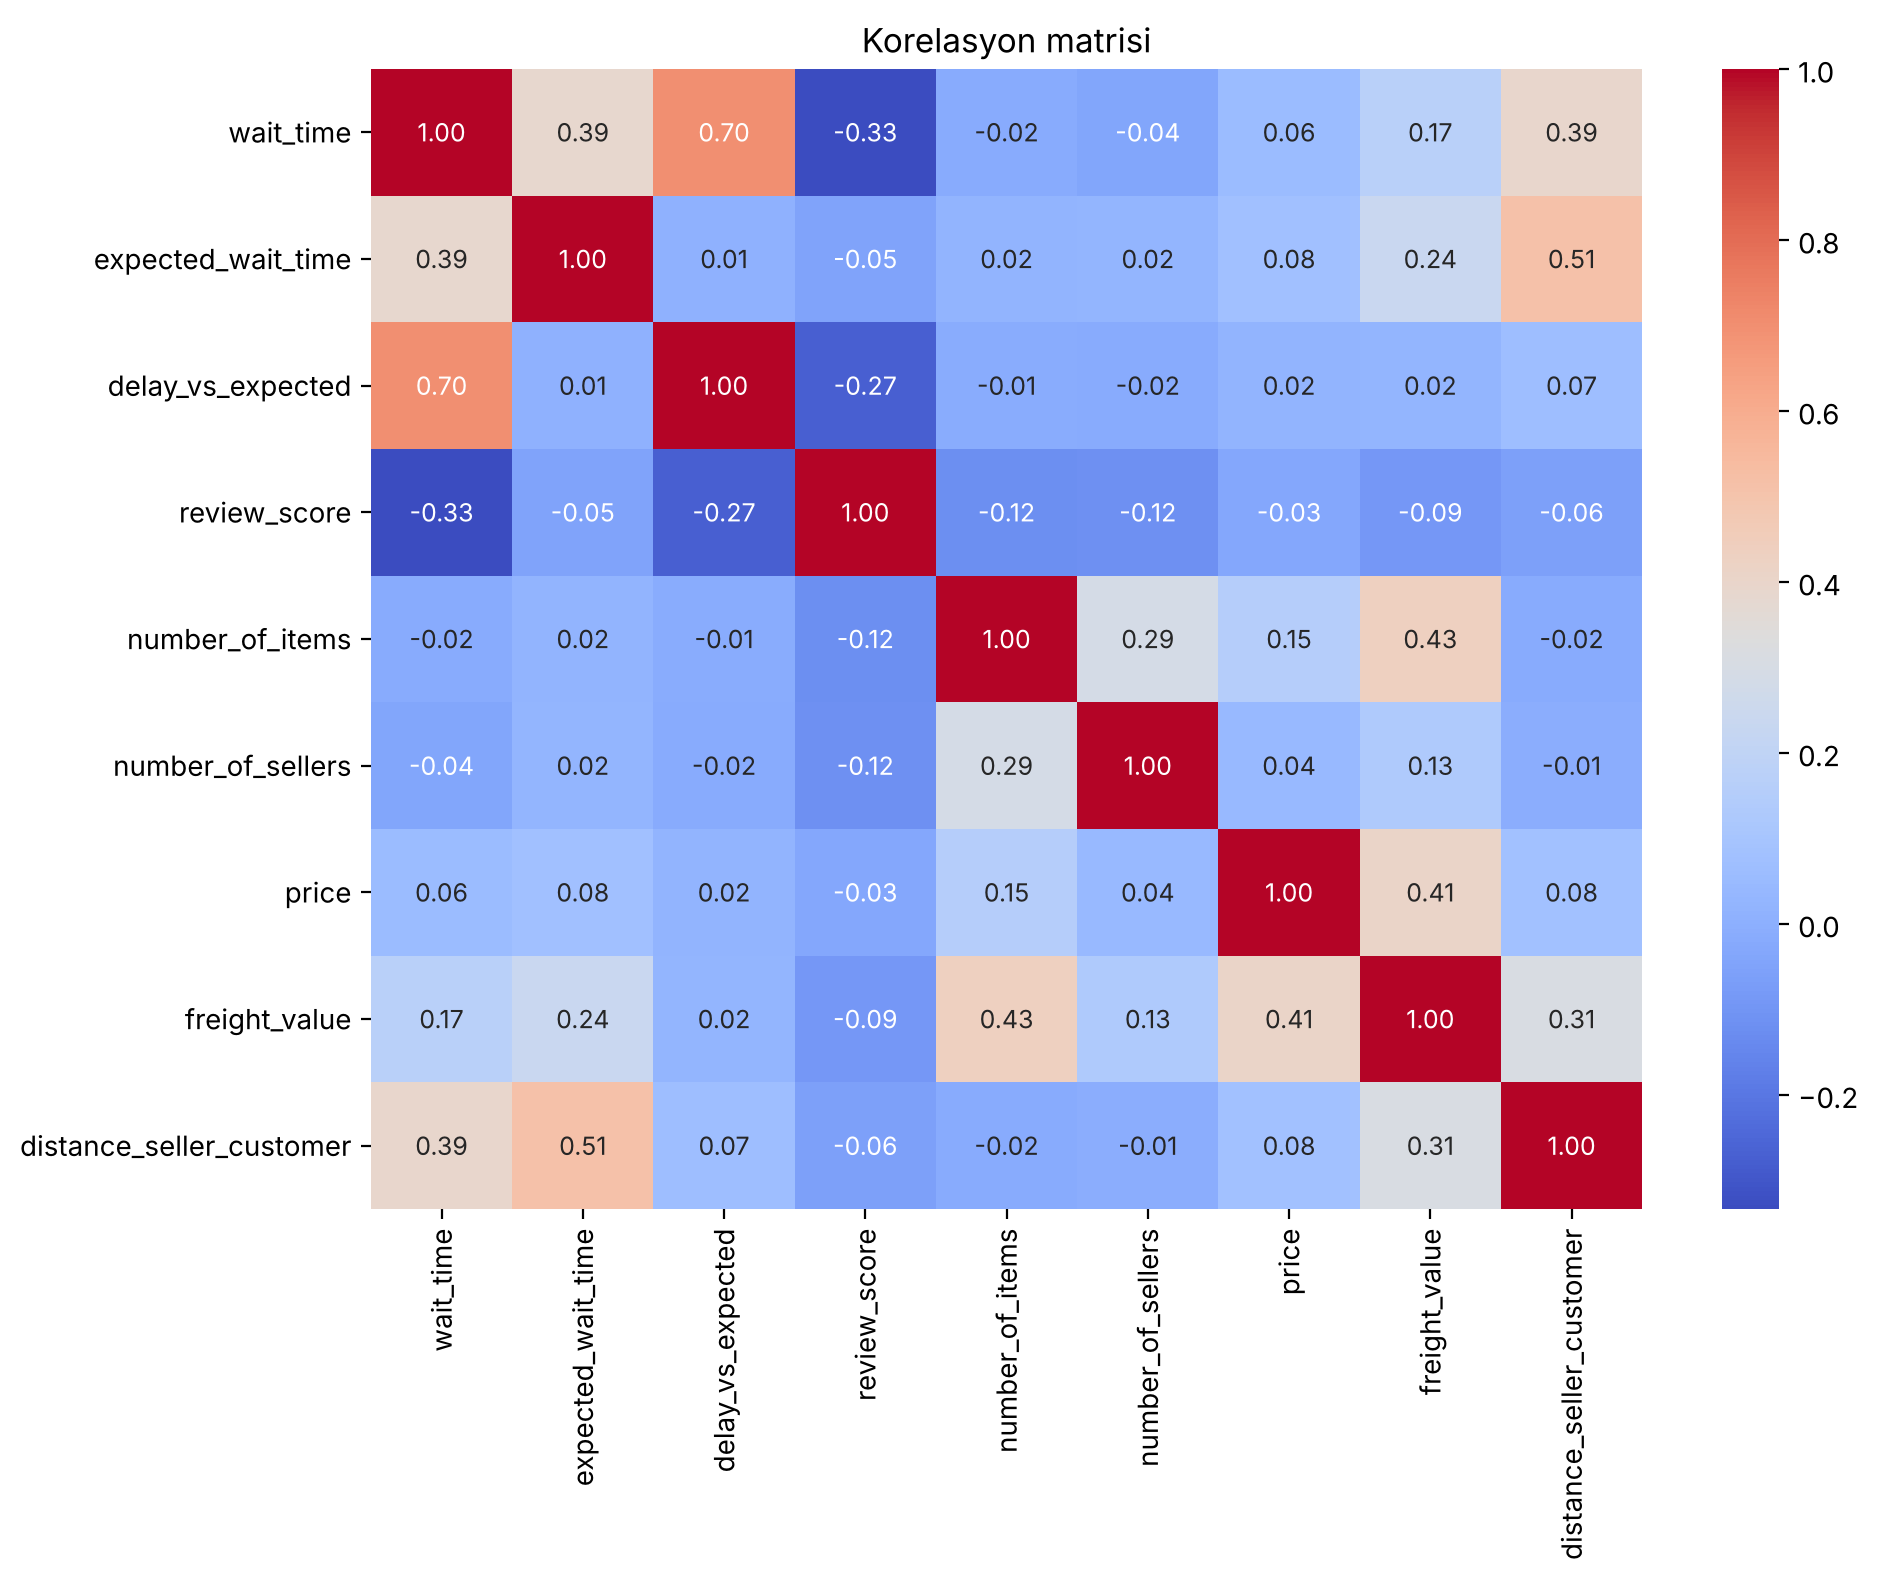

wait_time - delay_vs_expected korelasyonu: 0.703


In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(orders.drop(columns="order_id").corr(), cmap="coolwarm", annot=True, fmt=".2f", annot_kws={"size": 9})
plt.title("Korelasyon matrisi")
plt.tight_layout()
plt.show()

print("wait_time - delay_vs_expected korelasyonu:", round(orders["wait_time"].corr(orders["delay_vs_expected"]), 3))

In [7]:
model1 = smf.ols("review_score ~ wait_time", data=orders).fit()
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           review_score   R-squared:                       0.112
Model:                            OLS   Adj. R-squared:                  0.112
Method:                 Least Squares   F-statistic:                 1.204e+04
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:08:40   Log-Likelihood:            -1.5441e+05
No. Observations:               95870   AIC:                         3.088e+05
Df Residuals:                   95868   BIC:                         3.088e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.7237      0.006    727.900      0.000       4.711       4.736
wait_time     -0.0454      0.000   -109.731      0.000      -0.046      -0.045
==============================================================================
Omnibus:                    19553.088   Durbin-Watson:                   2.008
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            35455.564
Skew:                          -1.300   Prob(JB):                         0.00
Kurtosis:                       4.453   Cond. No.                         26.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [8]:
model2 = smf.ols("review_score ~ delay_vs_expected", data=orders).fit()
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           review_score   R-squared:                       0.074
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     7681.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:08:40   Log-Likelihood:            -1.5639e+05
No. Observations:               95870   AIC:                         3.128e+05
Df Residuals:                   95868   BIC:                         3.128e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.2121      0.004   1041.179      0.000       4.204       4.220
delay_vs_expected    -0.0752      0.001    -87.644      0.000      -0.077      -0.073
==============================================================================
Omnibus:                    20662.510   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            49771.345
Skew:                          -1.203   Prob(JB):                         0.00
Kurtosis:                       5.582   Cond. No.                         4.78
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [9]:
model3 = smf.ols("review_score ~ wait_time + delay_vs_expected", data=orders).fit()
model3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           review_score   R-squared:                       0.114
Model:                            OLS   Adj. R-squared:                  0.114
Method:                 Least Squares   F-statistic:                     6191.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:08:40   Log-Likelihood:            -1.5426e+05
No. Observations:               95870   AIC:                         3.085e+05
Df Residuals:                   95867   BIC:                         3.086e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.6502      0.008    601.566      0.000       4.635       4.665
wait_time            -0.0383      0.001    -65.971      0.000      -0.039      -0.037
delay_vs_expected    -0.0205      0.001    -17.415      0.000      -0.023      -0.018
==============================================================================
Omnibus:                    19995.857   Durbin-Watson:                   2.008
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            40514.405
Skew:                          -1.249   Prob(JB):                         0.00
Kurtosis:                       4.976   Cond. No.                         31.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [10]:
rows = []
for name, model in [("model1", model1), ("model2", model2), ("model3", model3)]:
    ci = model.conf_int()
    for var in model.params.index.drop("Intercept"):
        rows.append({
            "model": name,
            "değişken": var,
            "eğim": model.params[var],
            "ga_alt": ci.loc[var, 0],
            "ga_üst": ci.loc[var, 1],
            "t": model.tvalues[var],
            "p": model.pvalues[var],
            "R2": model.rsquared,
        })

pd.DataFrame(rows).round(4)

,model,değişken,eğim,ga_alt,ga_üst,t,p,R2
0,model1,wait_time,-0.0454,-0.0462,-0.0446,-109.7314,0.0,0.1116
1,model2,delay_vs_expected,-0.0752,-0.0768,-0.0735,-87.6439,0.0,0.0742
2,model3,wait_time,-0.0383,-0.0394,-0.0372,-65.9707,0.0,0.1144
3,model3,delay_vs_expected,-0.0205,-0.0228,-0.0182,-17.4151,0.0,0.1144


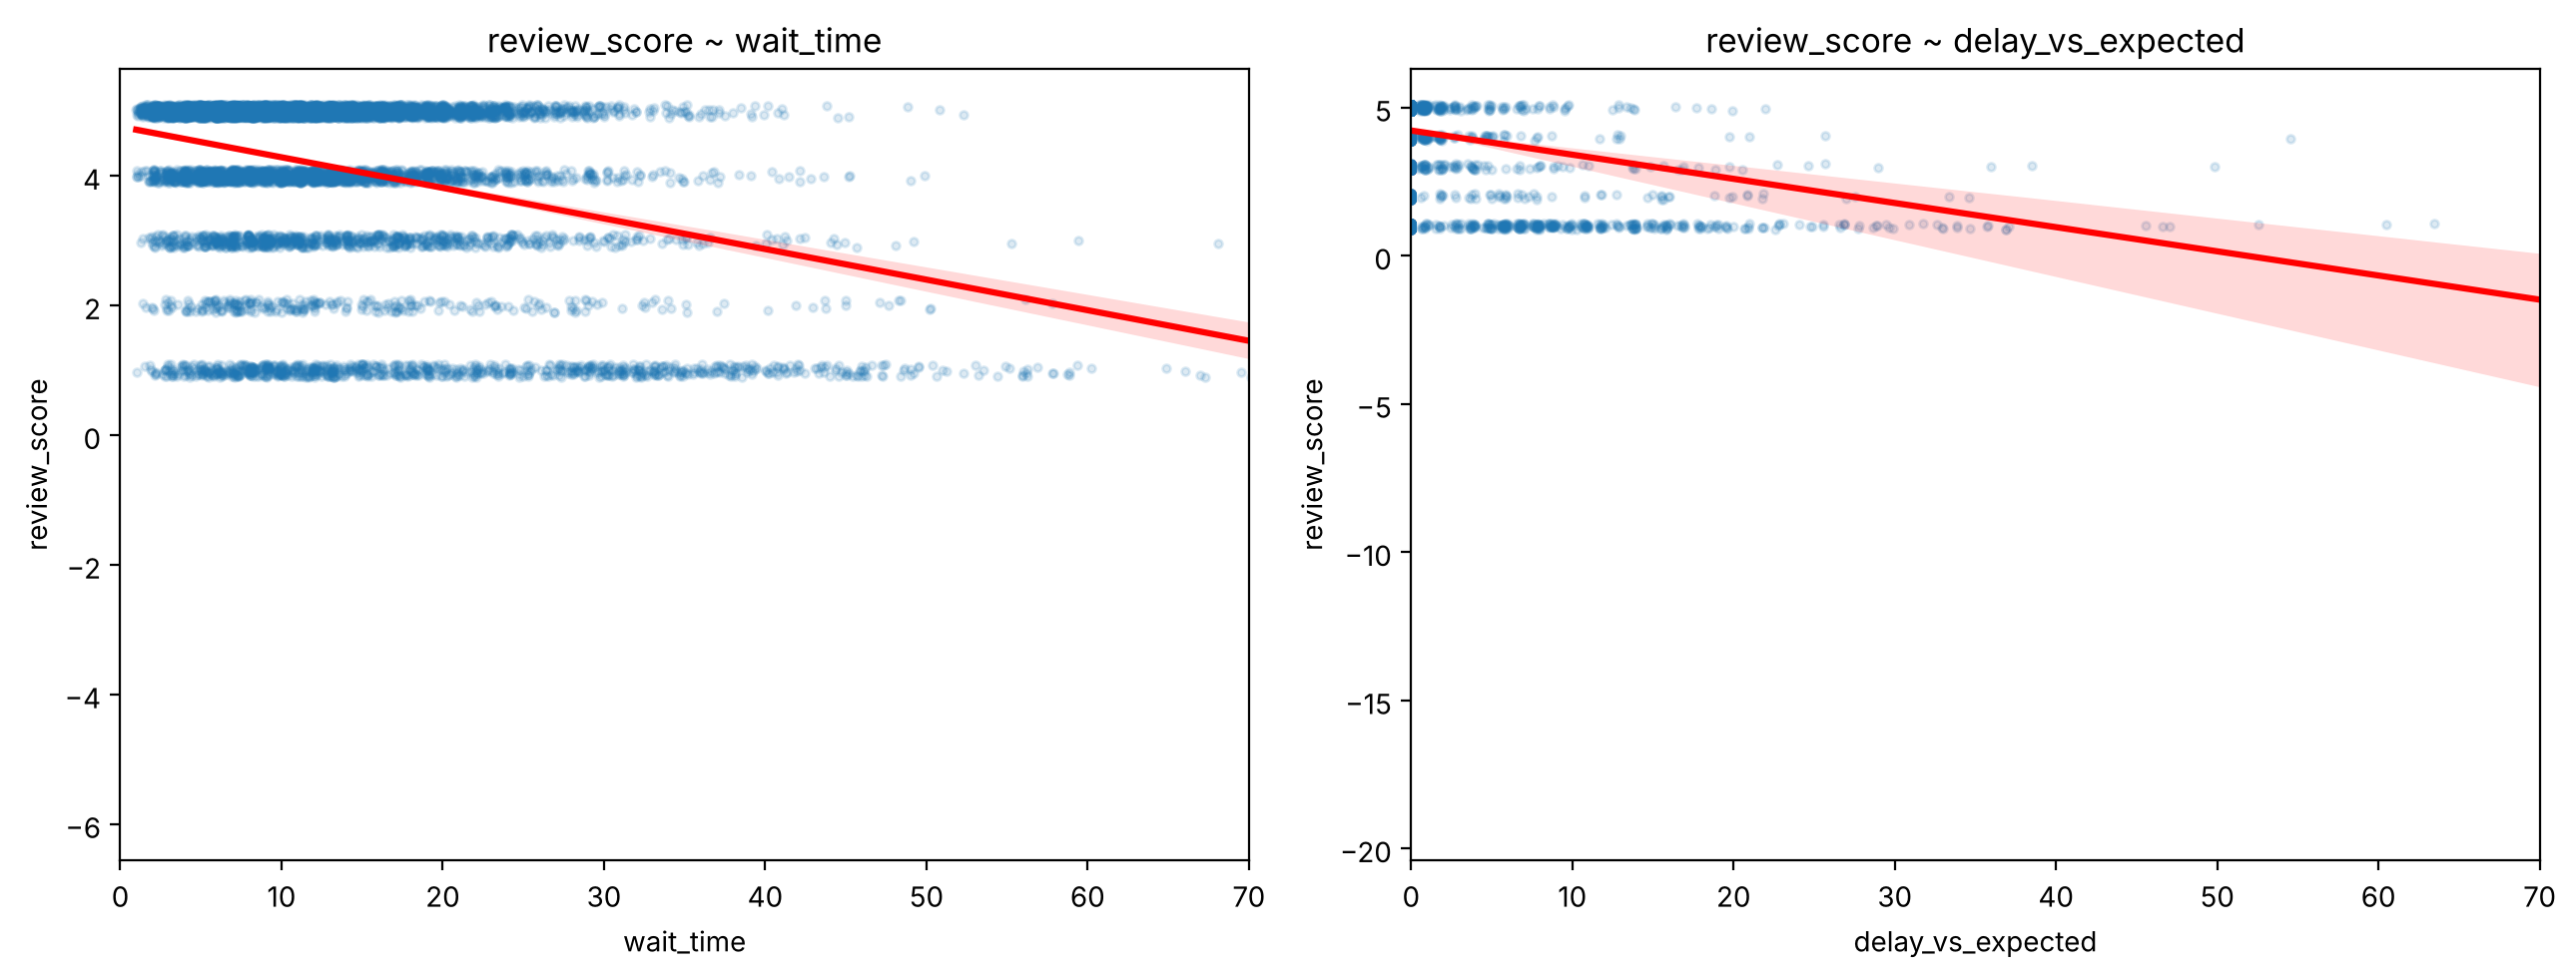

In [11]:
sample = orders.sample(10000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.regplot(x=sample["wait_time"], y=sample["review_score"], y_jitter=0.1, ci=95, scatter_kws={"alpha": 0.15, "s": 8}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_xlim(0, 70)
axes[0].set_title("review_score ~ wait_time")
sns.regplot(x=sample["delay_vs_expected"], y=sample["review_score"], y_jitter=0.1, ci=95, scatter_kws={"alpha": 0.15, "s": 8}, line_kws={"color": "red"}, ax=axes[1])
axes[1].set_xlim(0, 70)
axes[1].set_title("review_score ~ delay_vs_expected")
plt.tight_layout()
plt.show()

In [12]:
features = ["wait_time", "delay_vs_expected", "number_of_items", "number_of_sellers", "price", "freight_value", "distance_seller_customer"]

orders_standardized = (orders[features] - orders[features].mean()) / orders[features].std()
orders_standardized["review_score"] = orders["review_score"]

model4 = smf.ols("review_score ~ " + " + ".join(features), data=orders_standardized).fit()
model4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           review_score   R-squared:                       0.145
Model:                            OLS   Adj. R-squared:                  0.145
Method:                 Least Squares   F-statistic:                     2322.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:08:41   Log-Likelihood:            -1.5257e+05
No. Observations:               95870   AIC:                         3.052e+05
Df Residuals:                   95862   BIC:                         3.052e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                    4.1555      0.004   1082.719      0.000       4.148       4.163
wait_time                   -0.4397      0.006    -70.721      0.000      -0.452      -0.428
delay_vs_expected           -0.0515      0.006     -9.023      0.000      -0.063      -0.040
number_of_items             -0.1296      0.004    -28.921      0.000      -0.138      -0.121
number_of_sellers           -0.1314      0.004    -32.747      0.000      -0.139      -0.124
price                       -0.0029      0.004     -0.682      0.495      -0.011       0.005
freight_value                0.0041      0.005      0.838      0.402      -0.006       0.014
distance_seller_customer     0.0968      0.005     21.020      0.000       0.088       0.106
==============================================================================
Omnibus:                    18749.935   Durbin-Watson:                   2.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            37822.169
Skew:                          -1.175   Prob(JB):                         0.00
Kurtosis:                       4.986   Cond. No.                         3.02
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

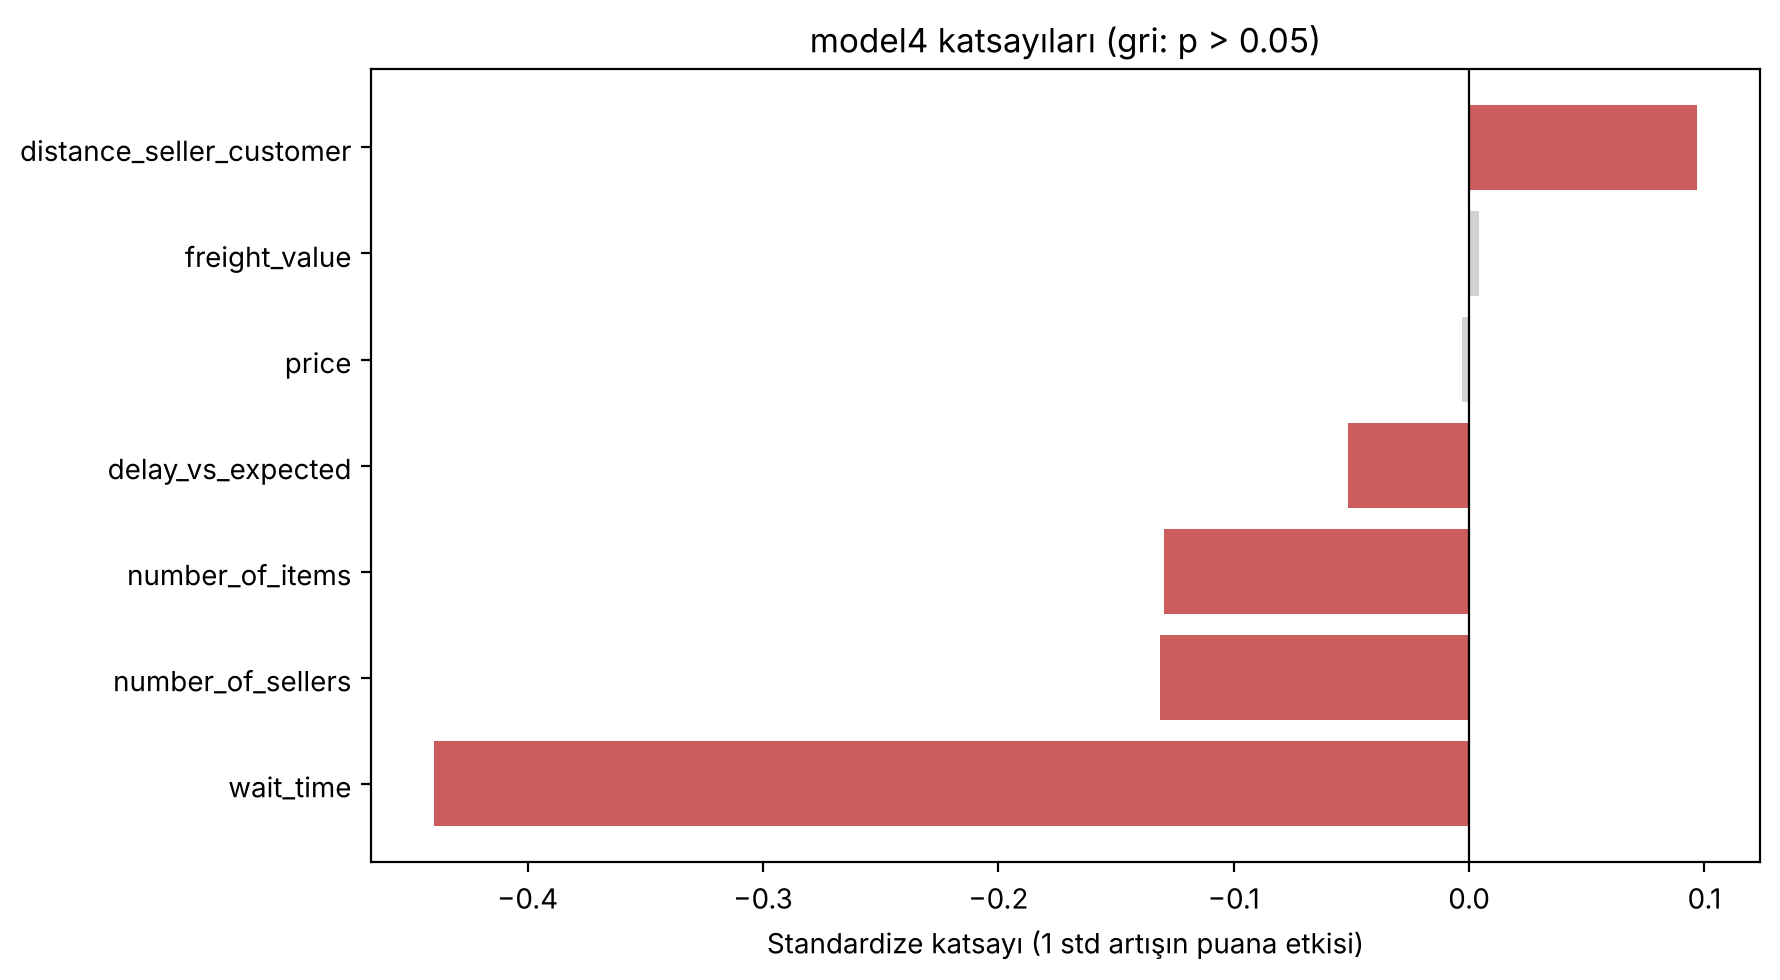

R2: model3 = 0.114 | model4 = 0.145
F-istatistiği: 2321.9 | p = 0.00e+00


In [13]:
coefs = model4.params.drop("Intercept").sort_values()
colors = ["indianred" if model4.pvalues[c] < 0.05 else "lightgray" for c in coefs.index]

plt.figure(figsize=(9, 5))
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardize katsayı (1 std artışın puana etkisi)")
plt.title("model4 katsayıları (gri: p > 0.05)")
plt.tight_layout()
plt.show()

print(f"R2: model3 = {model3.rsquared:.3f} | model4 = {model4.rsquared:.3f}")
print(f"F-istatistiği: {model4.fvalue:.1f} | p = {model4.f_pvalue:.2e}")

In [14]:
predicted_review_score = model4.predict(orders_standardized)
residuals = orders_standardized["review_score"] - predicted_review_score

print("Kalıntı ortalaması:", round(residuals.mean(), 6))
print("RMSE:", round(np.sqrt((residuals ** 2).mean()), 3))
print("review_score standart sapması:", round(orders["review_score"].std(), 3))
print("Tahmin aralığı:", round(predicted_review_score.min(), 2), "-", round(predicted_review_score.max(), 2))
print("1'in altındaki tahmin sayısı:", int((predicted_review_score < 1).sum()))

Kalıntı ortalaması: 0.0
RMSE: 1.188
review_score standart sapması: 1.285
Tahmin aralığı: -7.03 - 5.03
1'in altındaki tahmin sayısı: 167


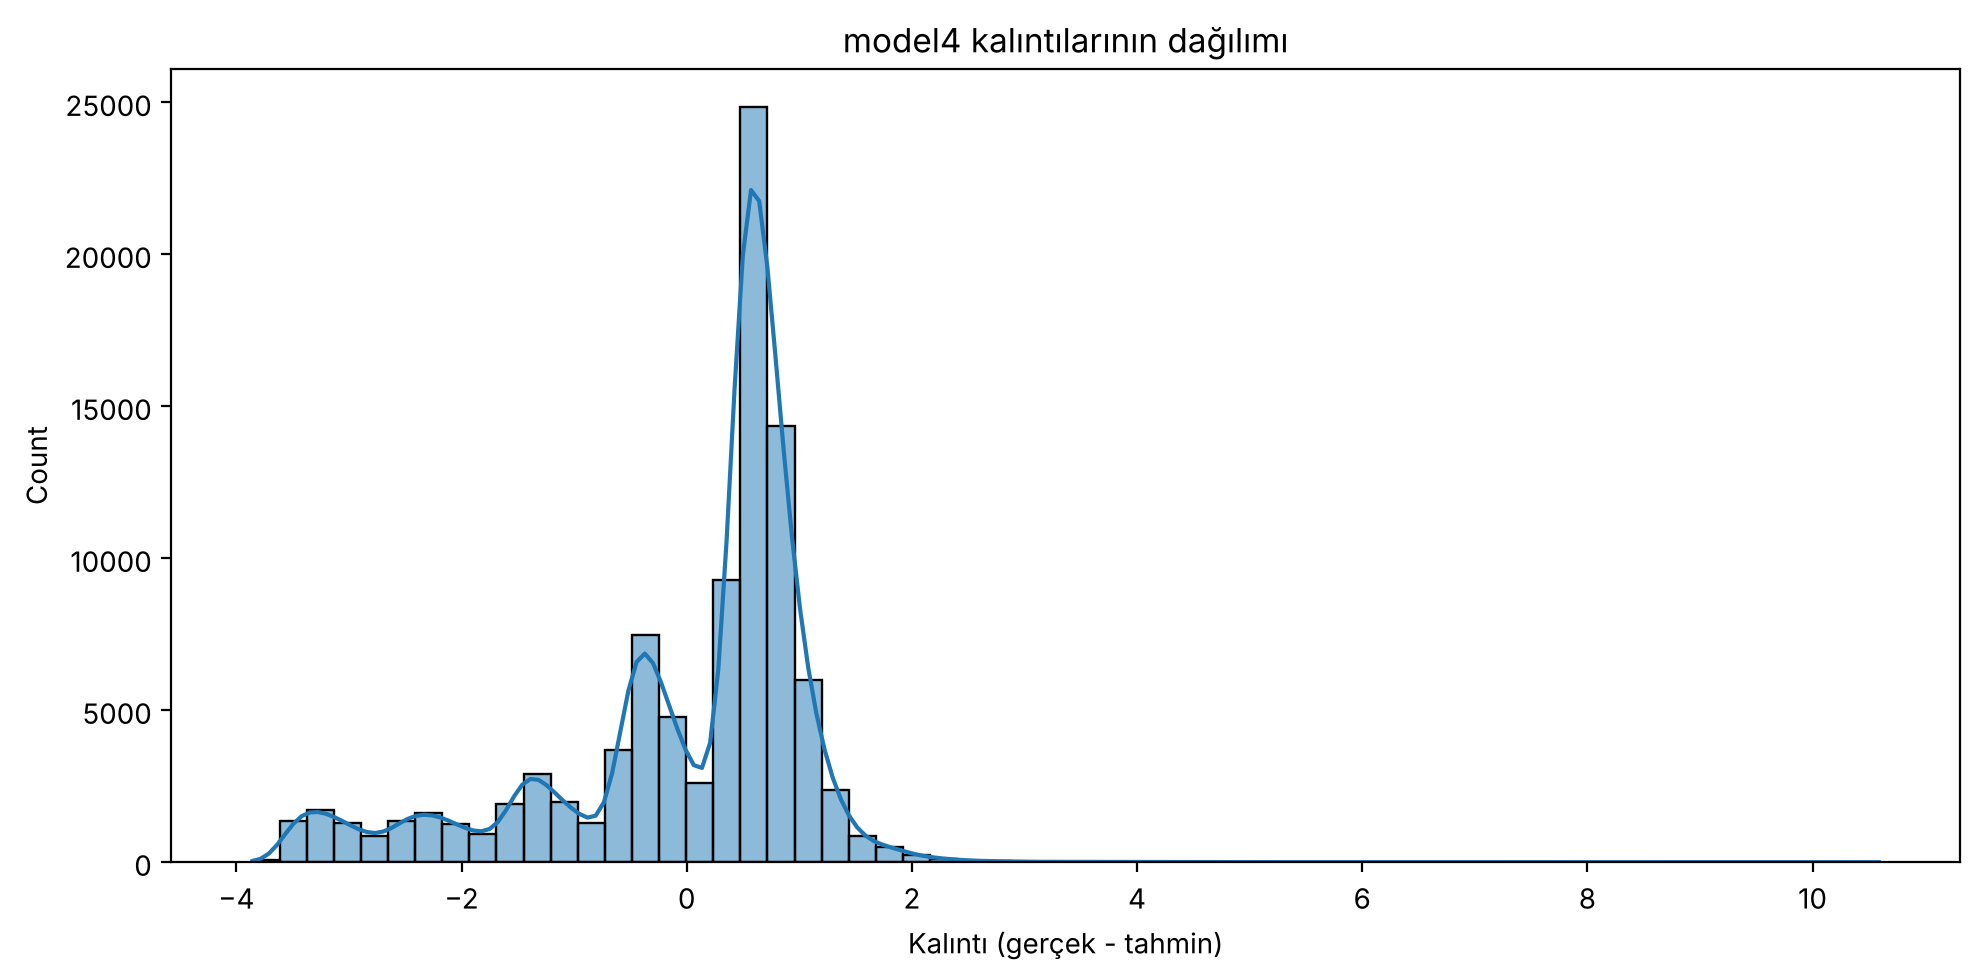

In [15]:
plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=60, kde=True)
plt.xlabel("Kalıntı (gerçek - tahmin)")
plt.title("model4 kalıntılarının dağılımı")
plt.tight_layout()
plt.show()

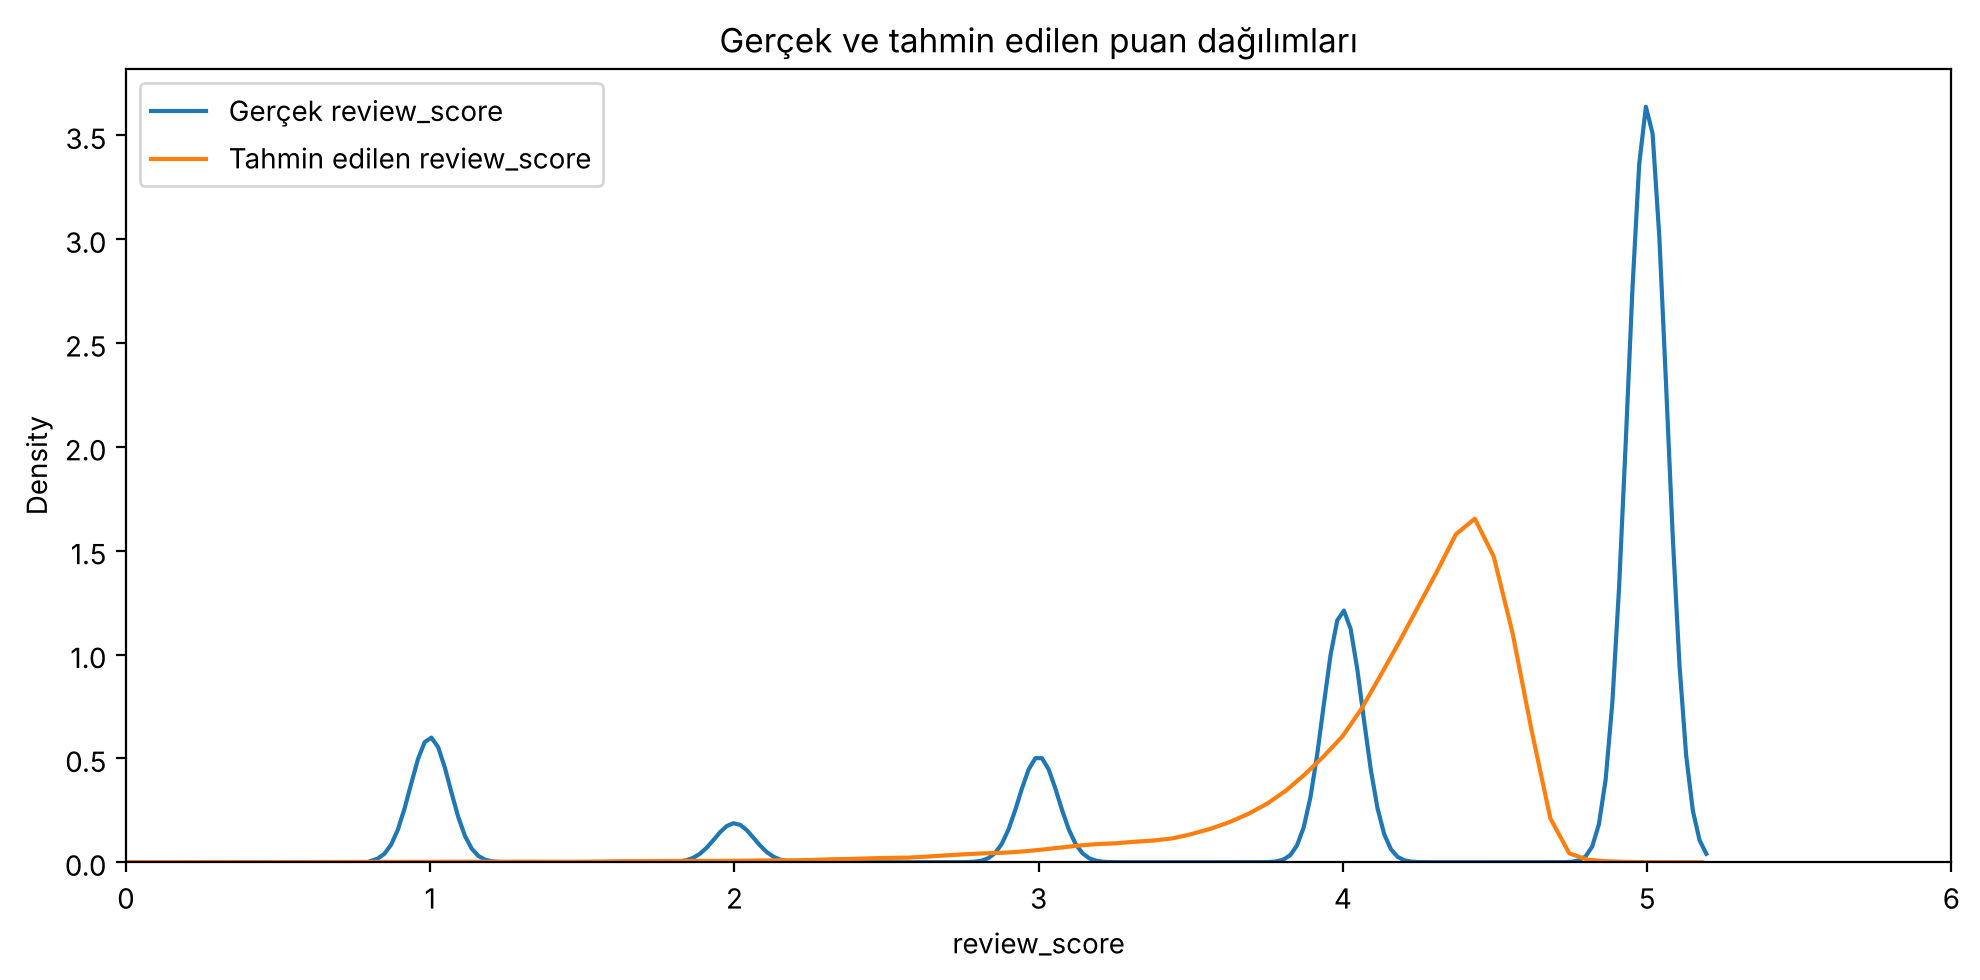

In [16]:
plt.figure(figsize=(10, 5))
sns.kdeplot(orders["review_score"], label="Gerçek review_score", bw_adjust=0.5)
sns.kdeplot(predicted_review_score, label="Tahmin edilen review_score")
plt.xlim(0, 6)
plt.legend()
plt.title("Gerçek ve tahmin edilen puan dağılımları")
plt.tight_layout()
plt.show()

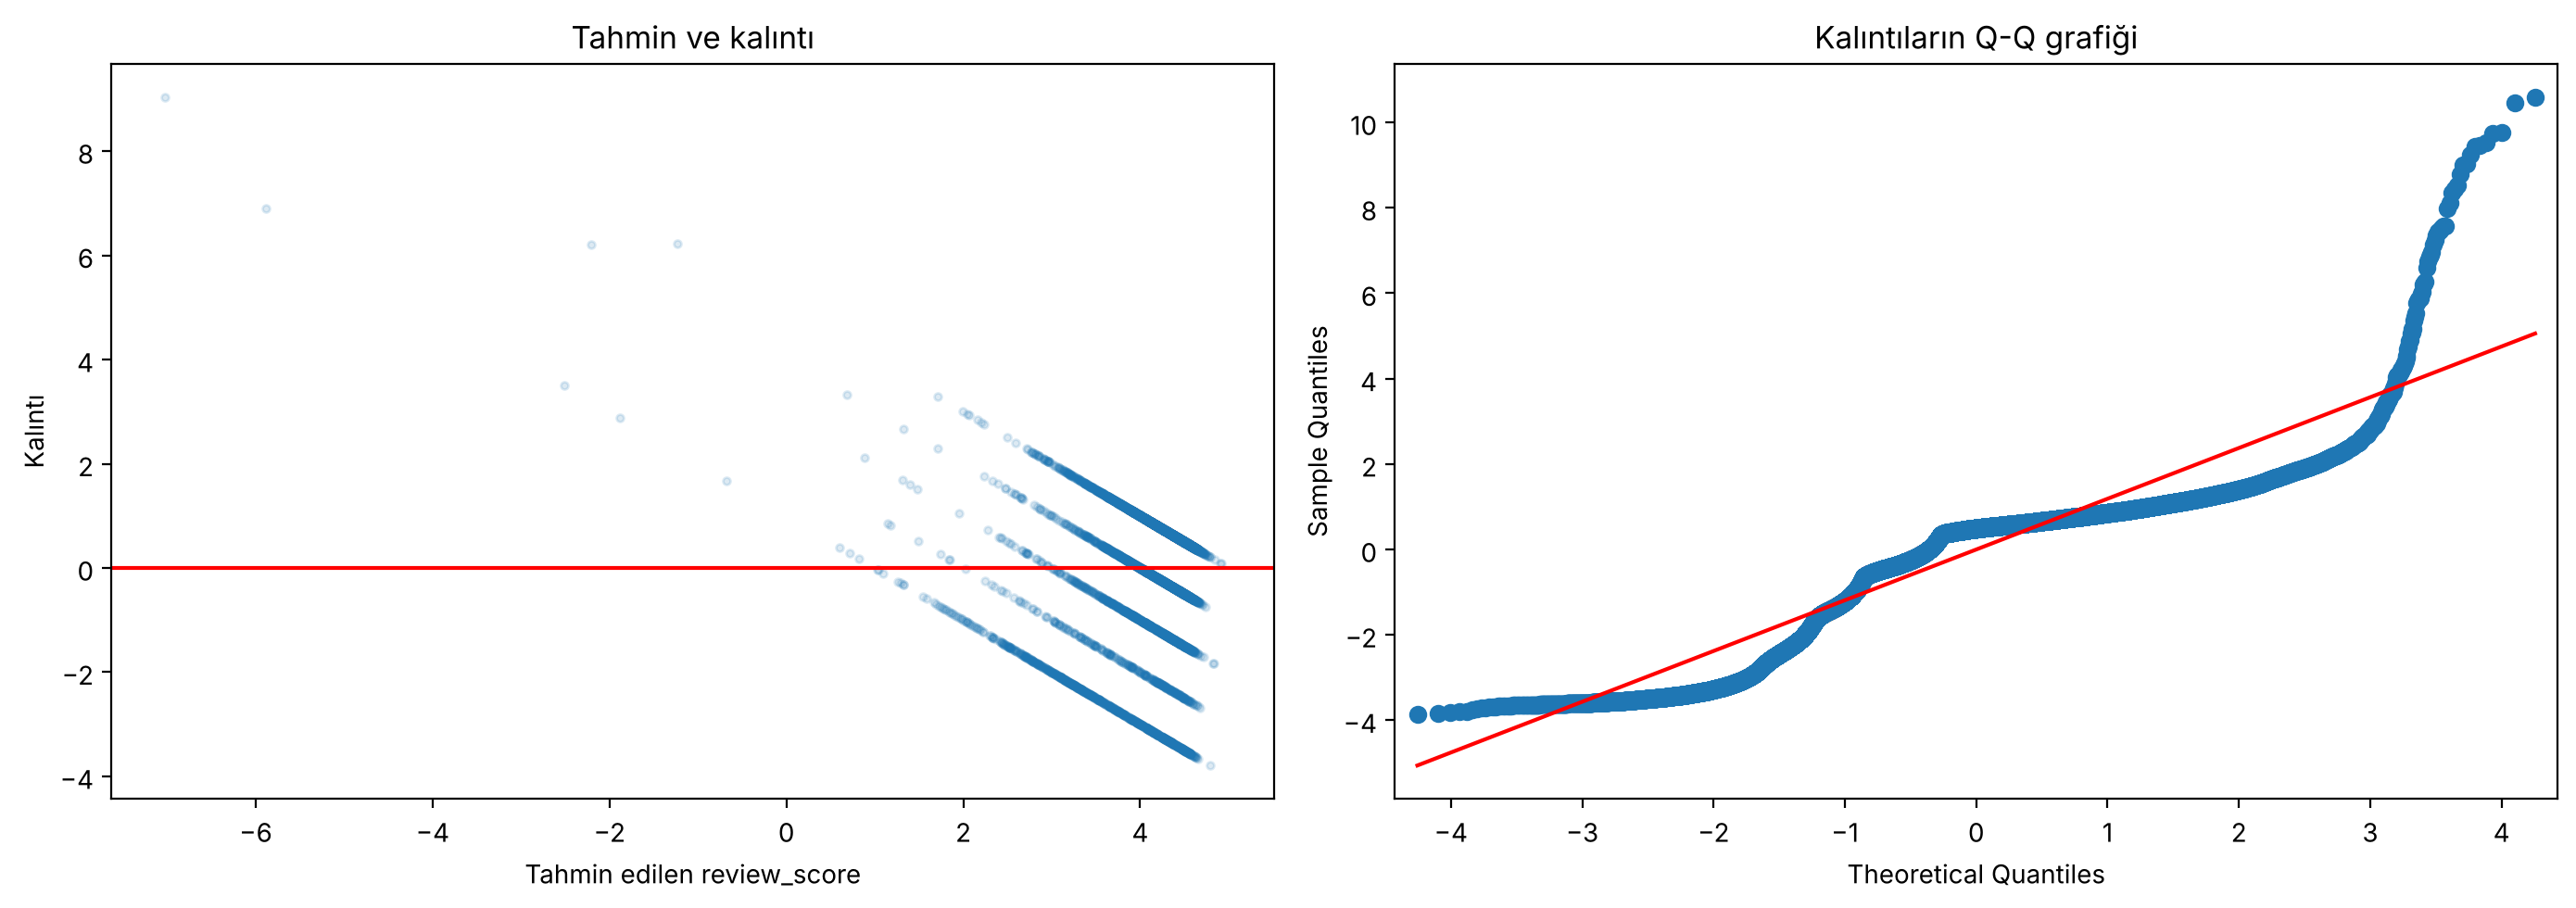

In [17]:
idx = orders_standardized.sample(10000, random_state=42).index

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(predicted_review_score[idx], residuals[idx], alpha=0.15, s=8)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Tahmin edilen review_score")
axes[0].set_ylabel("Kalıntı")
axes[0].set_title("Tahmin ve kalıntı")
sm.qqplot(residuals, line="s", ax=axes[1])
axes[1].set_title("Kalıntıların Q-Q grafiği")
plt.tight_layout()
plt.show()

In [18]:
orders["low_score"] = (orders["review_score"] <= 2).astype(int)
logit = smf.logit("low_score ~ wait_time + delay_vs_expected", data=orders).fit(disp=False)

odds = pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "ga_alt": np.exp(logit.conf_int()[0]),
    "ga_üst": np.exp(logit.conf_int()[1]),
    "p": logit.pvalues,
}).drop("Intercept")

print("Düşük puan (1-2) oranı:", round(orders["low_score"].mean() * 100, 1), "%")
print("Pseudo R2:", round(logit.prsquared, 3))
odds.round(4)

Düşük puan (1-2) oranı: 12.8 %
Pseudo R2: 0.112


,odds_ratio,ga_alt,ga_üst,p
wait_time,1.0576,1.0547,1.0605,0.0
delay_vs_expected,1.1040,1.0953,1.1127,0.0


## Sonuç

- **Veri:** Olist'in 6 tablosu (`orders`, `order_items`, `order_reviews`, `customers`, `sellers`, `geolocation`) birleştirildi. Yalnızca teslim edilmiş siparişler alındı, eksik değerler çıkarıldı, analiz 95.870 satırla yapıldı. `wait_time` satın alma ile teslim arasındaki gün, `delay_vs_expected` tahmini teslim tarihinden sonraki gecikme günü (erken teslimde 0). Puanların %59.2'si 5, %9.8'i 1 yıldız. `wait_time` ile `delay_vs_expected` arasındaki korelasyon 0.70, yani iki değişken büyük ölçüde aynı bilgiyi taşıyor.

- **Tek değişkenli regresyonlar:** `wait_time` için eğim -0.045 (%95 GA [-0.046, -0.045], t = -109.7, p < 0.001, R² = 0.112): her ek bekleme günü puanı ortalamada 0.045 düşürüyor. `delay_vs_expected` için eğim -0.075 (%95 GA [-0.077, -0.074], t = -87.6, p < 0.001, R² = 0.074): her ek gecikme günü puanı 0.075 düşürüyor. İki ilişki de negatif ve anlamlı, güven aralıkları dar ve 0'ı içermiyor. Regplot grafiklerindeki kırmızı doğrular aynı OLS doğruları.

- **Çok değişkenli regresyon (model3):** Diğeri sabitken `wait_time` eğimi -0.038 (%95 GA [-0.039, -0.037]), `delay_vs_expected` eğimi -0.021 (%95 GA [-0.023, -0.018]), ikisi de p < 0.001. Gecikmenin eğimi tek değişkenli modele göre yaklaşık 3.5 kat küçüldü. Tek başına bakınca gecikmeye yüklenen etkinin büyük kısmı aslında toplam bekleme süresinden geliyordu. Gecikmenin bekleme süresinden bağımsız küçük bir ek etkisi de var: müşteri hem uzun beklemeyi hem verilen tarihin tutmamasını ayrıca cezalandırıyor. R² 0.112'den yalnızca 0.114'e çıktı, gecikmenin bilgisi büyük ölçüde `wait_time`'ın içinde zaten var.

- **Daha fazla özellik (model4):** 7 özellik standardize edilip eklendi. `expected_wait_time`, `wait_time` ve `delay_vs_expected` ile neredeyse doğrusal bağlı olduğu için dışarıda bırakıldı. Puandan türetilen hiçbir değişken (ör. 1 veya 5 yıldız işareti) kullanılmadı. En güçlü özellik yine `wait_time` (-0.44), ardından `number_of_sellers` (-0.13) ve `number_of_items` (-0.13). `delay_vs_expected` -0.05'e indi ama anlamlı kaldı. `distance_seller_customer` +0.10: bekleme süresi sabitken uzak müşteriler daha yüksek puan veriyor, muhtemelen uzun teslimatı zaten bekliyorlar. `price` (p = 0.50) ve `freight_value` (p = 0.40) anlamlı değil. R² 0.145, F = 2321.9 (p ≈ 0): model bir bütün olarak anlamlı ama puan varyansının %85'inden fazlası bu veri setinde olmayan etkenlere bağlı.

- **Kalıntı analizi:** Kalıntı ortalaması 0 (OLS'de beklenen). RMSE 1.19 yıldız, puanın kendi standart sapması 1.29; yani model her siparişe ortalama puanı söylemekten çok az daha iyi. Kalıntı histogramı her puan sınıfı için ayrı bir tepeden oluşuyor (yaklaşık +0.7, -0.3, -1.3, -2.3, -3.3), sağda +10'a uzanan ince bir kuyruk var. Tahmin ve kalıntı grafiğinde noktalar 5 paralel çizgi halinde diziliyor, Q-Q grafiğinde iki kuyruk da çizgiden sapıyor. Normallik ve sabit varyans varsayımları sağlanmıyor. Tahminler -7.03 ile 5.03 arasında, 167 siparişte 1'in altında puan tahmin edildi. Tahminler 4 civarında toplanıyor, model 1-2 yıldızları neredeyse hiç ayırt edemiyor.

- **Alternatif model denemesi:** Hedef "düşük puan (1-2 yıldız, siparişlerin %12.8'i)" olarak ikiye ayrılıp lojistik regresyon kuruldu. Diğeri sabitken her ek bekleme günü düşük puan alma odds'unu %5.8 (OR 1.058, %95 GA [1.055, 1.061]), her ek gecikme günü %10.4 (OR 1.104, %95 GA [1.095, 1.113]) artırıyor. Doğrusal modelde ortalama puan üzerinde `wait_time` daha etkiliydi, ama kötü yorum alma riski açısından gün başına gecikme daha etkili. Yani gecikme ortalamayı az kaydırıyor ama müşteriyi 1-2 yıldıza itiyor.

- **Sınırlılıklar:** `review_score` 1-5 arasında sıralı bir kategori. Doğrusal regresyon bu yapıyı tanımıyor ve aralık dışı tahminler üretiyor. Kalıntı varsayımları sağlanmadığı için p-değerleri ve güven aralıkları yaklaşık kabul edilmeli (n ≈ 96 bin olduğu için katsayıların yönü yine güvenilir). Veri gözlemsel, sonuçlar nedensellik değil ilişki gösteriyor. Bazı siparişlerin birden fazla yorumu var ve hepsi ayrı satır olarak tutuldu.

- **Önerilen alternatifler:** Puan sıralamasını koruyan sıralı lojistik regresyon (`statsmodels` `OrderedModel`), burada denendiği gibi ikili lojistik regresyon (iş açısından en yorumlanabilir), doğrusal olmayan etkileri (ör. belli bir gecikme eşiğinden sonra sert düşüş) yakalayabilecek ağaç tabanlı sınıflandırıcılar (Random Forest, Gradient Boosting) ve siparişleri satıcı bazında toplayarak ortalama puanı sürekli bir hedef olarak modellemek.

- **Genel değerlendirme:** Teslimat hızının müşteri puanını düşürdüğüne dair istatistiksel kanıt güçlü. Kurulan her modelde (tek değişkenli, çok değişkenli, 7 özellikli, lojistik) teslimat süresi değişkenlerinin etkisi negatif ve p < 0.001. Ortalama puanı en çok toplam bekleme süresi düşürüyor, tahmini tarihin aşılması ise özellikle 1-2 yıldızlık yorum riskini artırıyor. Buna karşın teslimat süreleri puan varyansının yalnızca %11-15'ini açıklıyor.